value for W = 111.3798


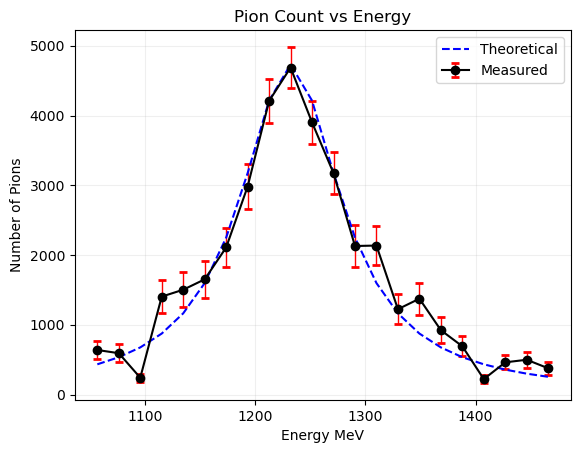

Optimal w from Curve fit = 113.6313 +- 2.2386
Random Sample estimate of w = 112.6609 ± 2.2287


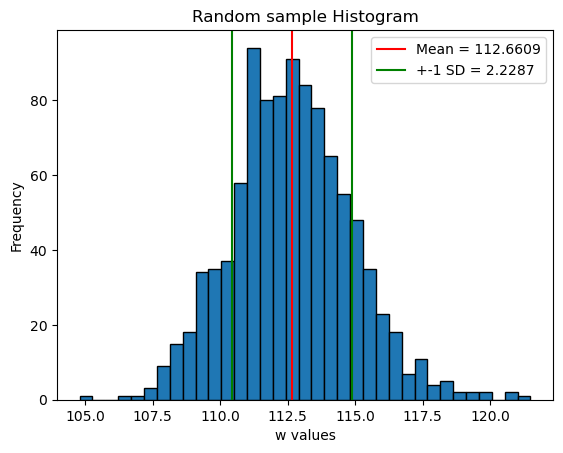

In [3]:
## Open and read data from file and create arrays from the data.

from numpy import array
import matplotlib . pyplot as plt
from numpy import *
from scipy . optimize import curve_fit

f = open ("data1.txt","r")
energy =[]; Npion =[]; Npionerr =[]
for line in f :
    estr , nstr , errstr = line . split ()
    energy . append ( float ( estr ))
    Npion . append ( float ( nstr ))
    Npionerr . append ( float ( errstr ))
f . close ()
energy = array ( energy )
Npion = array ( Npion )
Npionerr = array ( Npionerr )

## Plotting the data and changing graph apperance 

import matplotlib . pyplot as plt
from numpy import *

plt.errorbar(
    energy, Npion, yerr=Npionerr,
    color = "black",
    fmt = "o-",
    ecolor= "red",
    elinewidth=1,
    capsize=3,
    capthick=2,
label = "Measured")
plt.xlabel("Energy MeV")
plt.ylabel("Number of Pions")
plt.grid(True,alpha=0.2)
plt.title("Pion Count vs Energy")


##Now create theroetical values using the equation.

def theory(E, w,):
    
    return (( 1.467*10**7)/  ((w**2/4 )+(E - 1232)**2)  )
    
## Find a value for w using the midpoint of the data 

E_mid = energy[len(energy) // 2]
n_mid = Npion[len(energy) // 2]

w = sqrt(  4*( (1.467*10**7/n_mid) - (E_mid - 1232)**2   )  )  ## Rearanged eq for 

print(f"value for W = {w:.4f}")

## Call the function to get theoretical values
th = []
th = theory(energy, w)

plt.plot(energy, th, "b--", label="Theoretical")
plt.legend()
plt.savefig("PionCountvEnergy_Plot.png")
plt.show()

## Discrepencey calculation function for theretical values

def discrepancy(w):
    th = therory(energy,w)
    residuals = Npion - th
    return sum((residuals/Npionerr)**2)

##Using Curve fit for estimation of w

popt, pcov = curve_fit(theory, energy, Npion, sigma = Npionerr, p0 = w, absolute_sigma = True)

w_optimal = popt[0]
w_err = sqrt(pcov[0,0])
print(f"Optimal w from Curve fit = {w_optimal:.4f} +- {w_err:.4f}")

##Using random sampling we can simulate the experiment multiple times

w_values = []


for i in range(1000):
    simulated_data = random.normal(Npion, Npionerr)

    popt, pcov = curve_fit(theory, energy, simulated_data, p0=[w])
    w_values.append(popt[0])


## Use simulated data to find a value for w with err


w_mean = mean(w_values)
w_std = std(w_values)

print(f"Random Sample estimate of w = {w_mean:.4f} ± {w_std:.4f}")

## Histogram of Random samples


plt.hist(w_values, bins = 35, edgecolor= "black") ## changes how many bars on histogram
plt.xlabel("w values")
plt.ylabel("Frequency")
plt.title("Random sample Histogram" )
plt.axvline(w_mean, color = "red" , label=f"Mean = {w_mean:.4f}") ## adds a line for the mean
plt.axvline(w_mean - w_std, color="green", label=f"+-1 SD = {w_std:.4f}")
plt.axvline(w_mean + w_std, color="green")
plt.legend()
plt.savefig("Histogram_Plot.png")
plt.show()
        
    

